In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import sys
sys.path.append('../src')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# JAX imports
import jax
import jax.numpy as jnp
import optax
from flax import nnx
import gymnax

# Custom imports
from jaxrl.models.mlp import MLP
from jaxrl.actor_critic import compute_td_error, actor_train_step, critic_train_step

In [3]:
# Hyperparameters
GAMMA = 0.99
ACTOR_LR = 0.001
CRITIC_LR = 0.001
NUM_EPISODES = 1000
CHECK_STEP = 100
SEED = 0

# Environment parameters
OBS_SPACE = 4
ACT_SPACE = 2

# Random keys
main_key = jax.random.key(SEED)
main_key, actor_key, critic_key = jax.random.split(main_key, 3)

## Environment

In [4]:
env, env_params = gymnax.make("CartPole-v1")

## Model

In [5]:
actor = MLP(OBS_SPACE, ACT_SPACE, rngs=nnx.Rngs(actor_key))
critic = MLP(OBS_SPACE, 1, rngs=nnx.Rngs(critic_key))

## Optimizer

In [6]:
actor_optimizer = nnx.Optimizer(actor, optax.adam(ACTOR_LR), wrt=nnx.Param)
critic_optimizer = nnx.Optimizer(critic, optax.adam(CRITIC_LR), wrt=nnx.Param)

## Training

In [ ]:
history = {"episode": [], "actor_loss": [], "return": [], "critic_loss": []}

time_start = time.time()
for episode in range(NUM_EPISODES):
    main_key, reset_key = jax.random.split(main_key)
    obs, env_state = env.reset(reset_key, env_params)
    done = False
    episode_return = 0.0
    actor_losses, critic_losses = [], []

    while not done:
        # Prepare keys
        main_key, action_key, step_key = jax.random.split(main_key, 3)

        # Actor selects action
        action, _ = actor.sample(obs, action_key)

        # Environment step
        next_obs, env_state, reward, done, _ = env.step(step_key, env_state, action, env_params)

        # TD error
        td_error, td_target = compute_td_error(critic, obs, reward, next_obs, done, GAMMA)

        # Update critic on delta^2
        critic_loss = critic_train_step(critic, critic_optimizer, obs, td_target)

        # Update actor on -log_prob * delta
        actor_loss = actor_train_step(actor, actor_optimizer, obs, action, td_error)

        actor_losses.append(actor_loss)
        critic_losses.append(critic_loss)
        episode_return += float(reward)
        obs = next_obs
        done = bool(done)

    history["episode"].append(episode)
    history["actor_loss"].append(float(jnp.mean(jnp.stack(actor_losses))))
    history["return"].append(episode_return)
    history["critic_loss"].append(float(jnp.mean(jnp.stack(critic_losses))))

    if (episode + 1) % CHECK_STEP == 0:
        avg_return = sum(history["return"][-CHECK_STEP:]) / CHECK_STEP
        print(f"Episode {episode + 1:4d} | avg return (last {CHECK_STEP}): {avg_return:6.1f} "
              f"| actor loss: {history['actor_loss'][-1]:.4f} | critic loss: {history['critic_loss'][-1]:.4f}")

time_end = time.time()
print(f"Training completed in {time_end - time_start:.2f} seconds.")

Episode  100 | avg return (last 100):   11.1 | actor loss: 0.1195 | critic loss: 5.3945
Episode  200 | avg return (last 100):    9.8 | actor loss: 0.0729 | critic loss: 0.2073
Episode  300 | avg return (last 100):   56.0 | actor loss: -0.0369 | critic loss: 45.6455
Episode  400 | avg return (last 100):  110.4 | actor loss: -0.0460 | critic loss: 0.4705
Episode  500 | avg return (last 100):  128.5 | actor loss: -0.0126 | critic loss: 134.5721
Episode  600 | avg return (last 100):   11.9 | actor loss: -0.0009 | critic loss: 27.3243
Episode  700 | avg return (last 100):    9.4 | actor loss: -0.0012 | critic loss: 9.7272
Episode  800 | avg return (last 100):  186.9 | actor loss: -0.0475 | critic loss: 18.1822
Episode  900 | avg return (last 100):  172.5 | actor loss: -0.0823 | critic loss: 7.2751
Episode 1000 | avg return (last 100):  414.8 | actor loss: -0.0264 | critic loss: 14.2456
Training completed in 561.53 seconds.


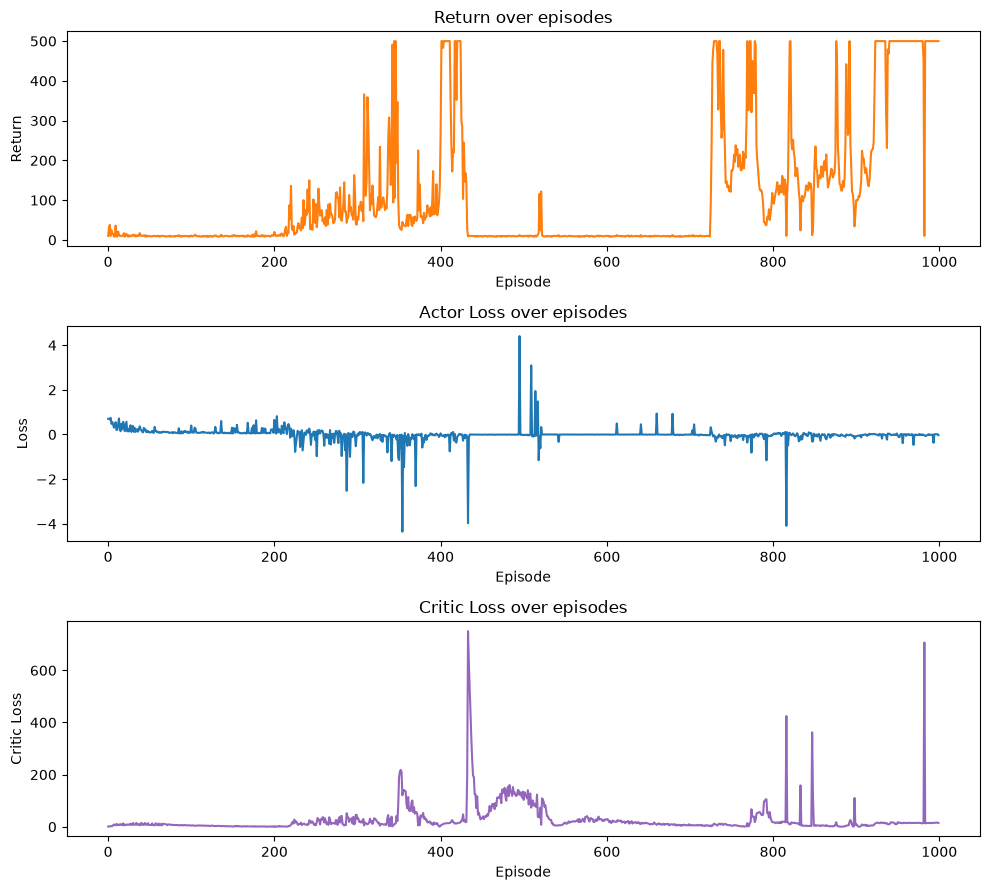

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].plot(history["episode"], history["return"], color='C1')
ax[0].set_xlabel("Episode")
ax[0].set_ylabel("Return")
ax[1].plot(history["episode"], history["actor_loss"], color='C0')
ax[1].set_xlabel("Episode")
ax[1].set_ylabel("Loss")
ax[2].plot(history["episode"], history["critic_loss"], color='C4')
ax[2].set_xlabel("Episode")
ax[2].set_ylabel("Critic Loss")
ax[0].set_title("Return over episodes")
ax[1].set_title("Actor Loss over episodes")
ax[2].set_title("Critic Loss over episodes")

plt.tight_layout()

In [ ]:
# Save history plot
plt.savefig("_results/actor_critic/training.png")
# Save history to json
import json
with open("_results/actor_critic/training.json", "w") as f:
    json.dump(history, f)

Episode return: 500 (500 frames) -> _results/actor_critic/cartpole.gif


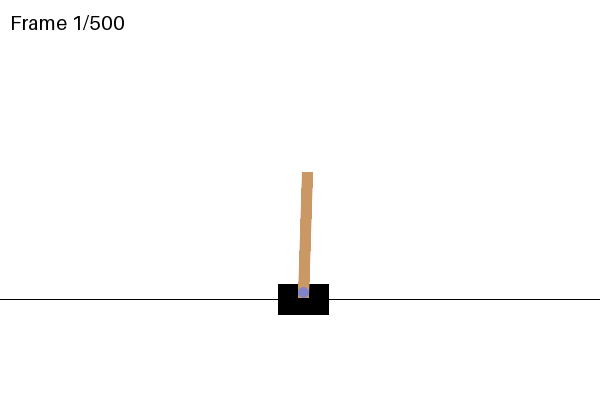

In [11]:
RENDER_SEED = 42

import gymnasium as gym
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as DisplayImage, display

GIF_PATH = "_results/actor_critic/cartpole.gif"

# Separate env that renders frames as RGB arrays
render_env = gym.make("CartPole-v1", render_mode="rgb_array")
# render_env.unwrapped.theta_threshold_radians = jnp.pi / 2
state, _ = render_env.reset(seed=RENDER_SEED)
done = False
frames, episode_return = [], 0.0

# Greedy rollout: take the most likely action to show what the policy learned
while not done:
    frames.append(render_env.render())
    action_probs = actor(jnp.asarray(state))
    action = int(jnp.argmax(action_probs))
    state, reward, terminated, truncated, _ = render_env.step(action)
    episode_return += reward
    done = terminated or truncated

render_env.close()

# Stamp the frame number in the top-left corner
font = ImageFont.load_default(size=20)
images = []
for i, frame in enumerate(frames):
    image = Image.fromarray(frame)
    ImageDraw.Draw(image).text((10, 10), f"Frame {i + 1}/{len(frames)}", fill=(0, 0, 0), font=font)
    images.append(image)

images[0].save(GIF_PATH, save_all=True, append_images=images[1:], duration=20, loop=0)

print(f"Episode return: {episode_return:.0f} ({len(frames)} frames) -> {GIF_PATH}")
display(DisplayImage(filename=GIF_PATH))